# 🔬 Complete Exploratory Data Analysis (EDA): HAM10000 Skin Lesion Dataset
**System**: Skin Cancer Detection and Classification System Using CNN-SVM  
**Author**: Deep Learning Research Team  
**Objective**: Perform exhaustive statistical, demographic, morphological, and computer vision profiling of the HAM10000 (Human Against Machine with 10,000 training images) dermoscopy benchmark.

### Table of Contents:
1. [Environment Setup & Data Ingestion](#1)
2. [Dataset Overview & Metadata Integrity](#2)
3. [Ground Truth Validation Mechanisms (dx_type)](#3)
4. [Diagnostic Class Distribution & Severe Imbalance](#4)
5. [Patient Demographics: Age & Sex Epidemiology](#5)
6. [Anatomical Localization & Cross-Feature Heatmaps](#6)
7. [Computer Vision & Color Channel Profiling](#7)
8. [Dermoscopic Gallery: Multi-Class Visual Inspection](#8)
9. [Diagnostic Mimics & Intra-Class Variability](#9)
10. [Key Clinical & Machine Learning Findings](#10)

In [1]:
# Environment Setup and Library Imports
import os, sys
project_root = os.path.abspath('..') if os.path.exists('../dataset') else os.path.abspath('.')
if project_root not in sys.path:
    sys.path.insert(0, project_root)
os.chdir(project_root)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from scipy import stats
from src.preprocessing import CLASS_NAMES, index_image_paths, SEVERITY_MAPPING

# Set global visualization styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.titlesize': 15,
    'figure.autolayout': True
})
print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: C:\Users\USER\OneDrive\Desktop\skincancer


<a id='2'></a>
## 1. Dataset Overview & Data Quality Assessment
We examine record counts, unique lesion identifiers, missing values, and duplicate image frequencies.

In [2]:
metadata_path = os.path.join('dataset', 'raw', 'HAM10000_metadata.csv')
df = pd.read_csv(metadata_path)

print(f'Total Rows (Images):         {len(df):,}')
print(f'Unique Lesions (Patients):   {df["lesion_id"].nunique():,}')
print(f'Duplicate Lesion Ratio:      {(1 - df["lesion_id"].nunique() / len(df)) * 100:.2f}%')
print(f'Missing Values per Column:\n{df.isnull().sum()}')

# Map full diagnosis name and severity
df['diagnosis_name'] = df['dx'].map(CLASS_NAMES)
df['severity'] = df['dx'].map(SEVERITY_MAPPING)
display(df.head(10))

Total Rows (Images):         10,015
Unique Lesions (Patients):   7,470
Duplicate Lesion Ratio:      25.41%
Missing Values per Column:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


,lesion_id,image_id,dx,dx_type,age,sex,localization,diagnosis_name,severity
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,Benign Keratosis,Benign
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,Benign Keratosis,Benign
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,Benign Keratosis,Benign
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,Benign Keratosis,Benign
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,Benign Keratosis,Benign
5,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,Benign Keratosis,Benign
6,HAM_0002761,ISIC_0029176,bkl,histo,60.0,male,face,Benign Keratosis,Benign
7,HAM_0002761,ISIC_0029068,bkl,histo,60.0,male,face,Benign Keratosis,Benign
8,HAM_0005132,ISIC_0025837,bkl,histo,70.0,female,back,Benign Keratosis,Benign
9,HAM_0005132,ISIC_0025209,bkl,histo,70.0,female,back,Benign Keratosis,Benign


### Lesion Re-imaging & Data Leakage Risk
In HAM10000, lesions often have multiple images taken at different times or angles. A random image split would leak identical lesions into test sets, artificially inflating accuracy.

,Images per Lesion,Number of Lesions,Total Resulting Images,Percentage of Lesions (%)
0,1,5514,5514,73.82
1,2,1423,2846,19.05
2,3,490,1470,6.56
3,4,34,136,0.46
4,5,5,25,0.07
5,6,4,24,0.05


2026-10-28 17:42:36,216 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-28 17:42:36,217 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


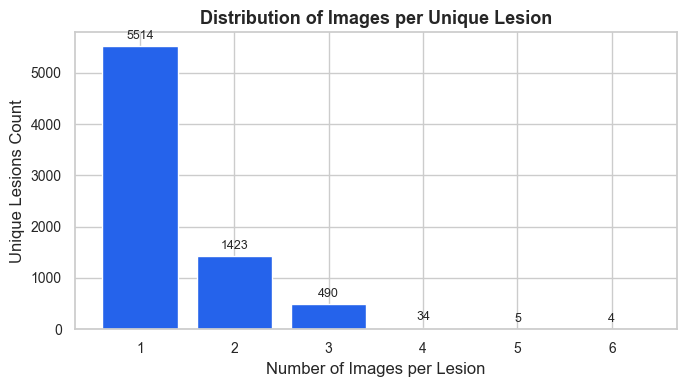

In [3]:
images_per_lesion = df.groupby('lesion_id')['image_id'].count().value_counts().sort_index()
disp_img_df = pd.DataFrame({
    'Images per Lesion': images_per_lesion.index,
    'Number of Lesions': images_per_lesion.values,
    'Total Resulting Images': images_per_lesion.index * images_per_lesion.values,
    'Percentage of Lesions (%)': (images_per_lesion.values / df['lesion_id'].nunique() * 100).round(2)
})
display(disp_img_df)

plt.figure(figsize=(7, 4))
bars = plt.bar(disp_img_df['Images per Lesion'].astype(str), disp_img_df['Number of Lesions'], color='#2563eb')
plt.title('Distribution of Images per Unique Lesion', fontweight='bold')
plt.xlabel('Number of Images per Lesion')
plt.ylabel('Unique Lesions Count')
for b in bars:
    h = b.get_height()
    plt.text(b.get_x() + b.get_width()/2.0, h + 80, f'{h}', ha='center', va='bottom', fontsize=9)
plt.show()

<a id='3'></a>
## 2. Ground Truth Validation Mechanisms (`dx_type`)
Diagnostic ground truth was established by 4 criteria:
- `histo`: Histopathology (gold standard tissue biopsy)
- `follow_up`: Digital dermatoscopic follow-up (monitoring lesion stability over time)
- `consensus`: Expert expert consensus
- `confocal`: In-vivo confocal microscopy

,Validation Method,Count,Proportion (%)
0,histo,5340,53.32
1,follow_up,3704,36.98
2,consensus,902,9.01
3,confocal,69,0.69


C:\Users\USER\AppData\Local\Temp\ipykernel_24460\3986143076.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='dx_type', order=dx_type_counts.index, palette='crest', ax=axes[0])


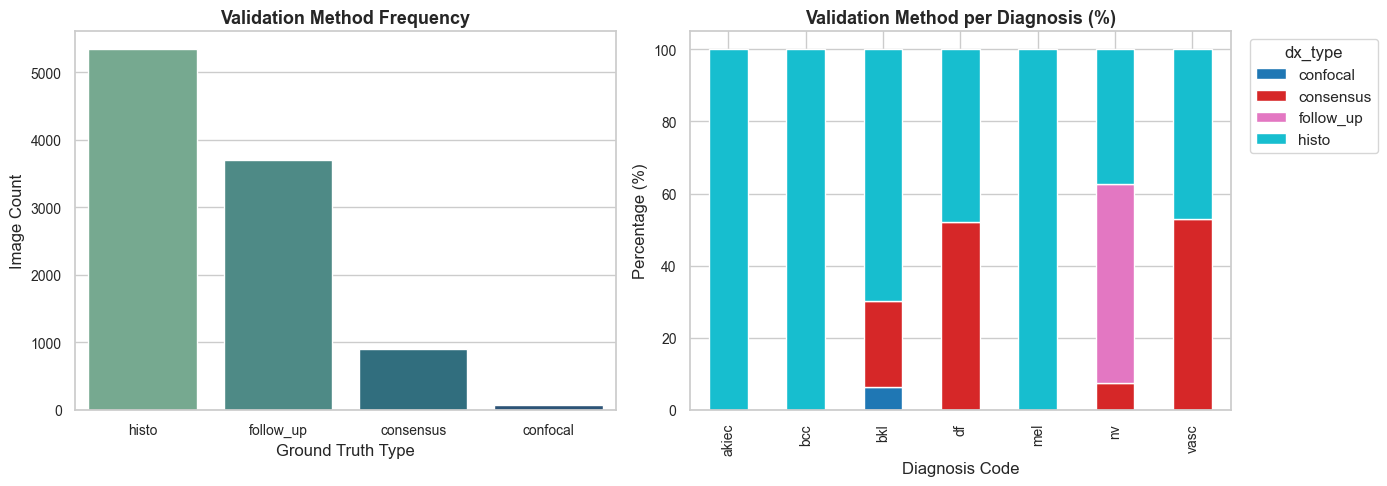

In [4]:
dx_type_counts = df['dx_type'].value_counts()
dx_type_df = pd.DataFrame({
    'Validation Method': dx_type_counts.index,
    'Count': dx_type_counts.values,
    'Proportion (%)': (dx_type_counts.values / len(df) * 100).round(2)
})
display(dx_type_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='dx_type', order=dx_type_counts.index, palette='crest', ax=axes[0])
axes[0].set_title('Validation Method Frequency', fontweight='bold')
axes[0].set_xlabel('Ground Truth Type')
axes[0].set_ylabel('Image Count')

# Stacked by diagnosis
cross_dx = pd.crosstab(df['dx'], df['dx_type'], normalize='index') * 100
cross_dx.plot(kind='bar', stacked=True, colormap='tab10', ax=axes[1])
axes[1].set_title('Validation Method per Diagnosis (%)', fontweight='bold')
axes[1].set_xlabel('Diagnosis Code')
axes[1].set_ylabel('Percentage (%)')
axes[1].legend(title='dx_type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

<a id='4'></a>
## 3. Diagnostic Class Distribution & Severe Imbalance
HAM10000 exhibits severe multi-class imbalance. Melanocytic nevi (`nv`) represent 66.9% of all samples, whereas dermatofibroma (`df`) represents only 1.1% (an imbalance ratio exceeding 58:1).

,Code,Diagnosis,Severity,Sample Count,Percentage (%),Imbalance Ratio (vs max)
0,nv,Melanocytic Nevi,Benign,6705,66.95,1.0
1,mel,Melanoma,Malignant,1113,11.11,6.0
2,bkl,Benign Keratosis,Benign,1099,10.97,6.1
3,bcc,Basal Cell Carcinoma,Malignant,514,5.13,13.0
4,akiec,Actinic Keratoses,Pre-cancerous / Malignant,327,3.27,20.5
5,vasc,Vascular Lesions,Benign,142,1.42,47.2
6,df,Dermatofibroma,Benign,115,1.15,58.3


C:\Users\USER\AppData\Local\Temp\ipykernel_24460\3828660489.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=class_summary, x='Sample Count', y='Diagnosis', palette='magma', ax=axes[0])


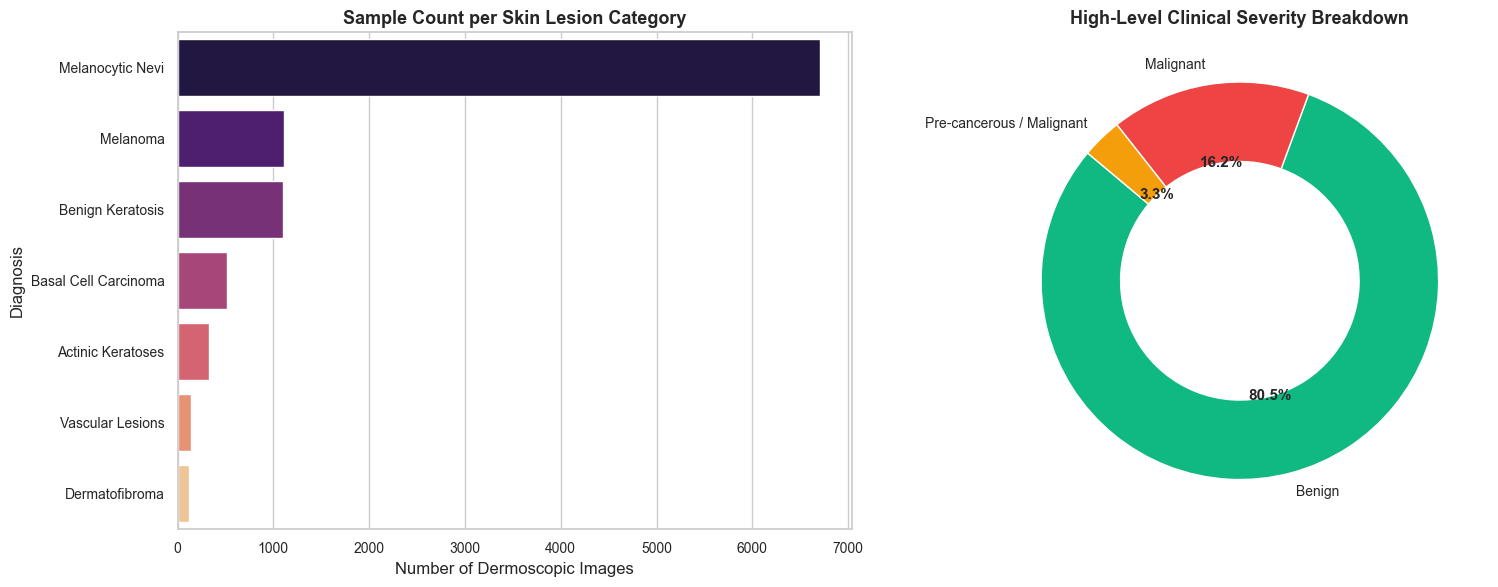

In [5]:
class_counts = df['dx'].value_counts()
class_summary = pd.DataFrame({
    'Code': class_counts.index,
    'Diagnosis': [CLASS_NAMES[c] for c in class_counts.index],
    'Severity': [SEVERITY_MAPPING[c] for c in class_counts.index],
    'Sample Count': class_counts.values,
    'Percentage (%)': (class_counts.values / len(df) * 100).round(2),
    'Imbalance Ratio (vs max)': (class_counts.max() / class_counts.values).round(1)
})
display(class_summary)

# Combined Bar and Donut Chart
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
palette = sns.color_palette('magma', len(class_counts))
sns.barplot(data=class_summary, x='Sample Count', y='Diagnosis', palette='magma', ax=axes[0])
axes[0].set_title('Sample Count per Skin Lesion Category', fontweight='bold')
axes[0].set_xlabel('Number of Dermoscopic Images')

# Severity Donut Chart
sev_counts = df['severity'].value_counts()
colors_sev = ['#10b981', '#ef4444', '#f59e0b']
wedges, texts, autotexts = axes[1].pie(
    sev_counts.values,
    labels=sev_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors_sev,
    wedgeprops=dict(width=0.4, edgecolor='w')
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
axes[1].set_title('High-Level Clinical Severity Breakdown', fontweight='bold')
plt.tight_layout()
plt.show()

<a id='5'></a>
## 4. Patient Demographics: Age & Sex Epidemiology
Skin cancer risk correlates strongly with age and cumulative ultraviolet (UV) radiation exposure. Here we explore age distributions across diagnostic categories and gender disparities.

Age Summary Statistics (Years):


,count,mean,std,min,25%,50%,75%,max
dx,,,,,,,,
akiec,327.0,66.5,11.5,30.0,60.0,70.0,75.0,85.0
bcc,514.0,66.8,13.7,20.0,60.0,70.0,75.0,85.0
bkl,1089.0,64.3,14.1,0.0,55.0,65.0,75.0,85.0
df,115.0,53.0,13.6,25.0,45.0,50.0,65.0,80.0
mel,1111.0,60.7,15.2,5.0,50.0,60.0,70.0,85.0
nv,6660.0,46.5,15.2,0.0,35.0,45.0,55.0,85.0
vasc,142.0,51.4,21.6,0.0,40.0,55.0,70.0,85.0


C:\Users\USER\AppData\Local\Temp\ipykernel_24460\90390041.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid_age_df, y='diagnosis_name', x='age', order=order_by_median_age, palette='coolwarm', ax=axes[0])


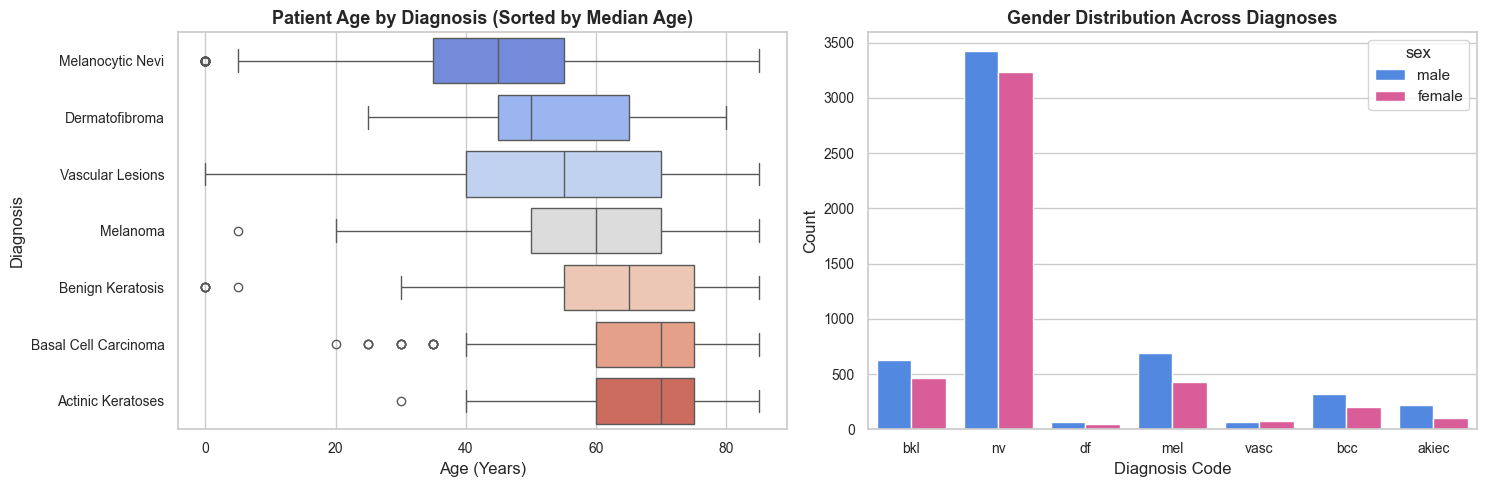

Chi-Square Test (Severity vs Sex): Chi2=74.51, p-value=6.61e-17
Finding: Significant correlation between sex and lesion severity (p < 0.05).


In [6]:
valid_age_df = df.dropna(subset=['age']).copy()
print('Age Summary Statistics (Years):')
display(valid_age_df.groupby('dx')['age'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Age boxplot by diagnosis
order_by_median_age = valid_age_df.groupby('diagnosis_name')['age'].median().sort_values().index
sns.boxplot(data=valid_age_df, y='diagnosis_name', x='age', order=order_by_median_age, palette='coolwarm', ax=axes[0])
axes[0].set_title('Patient Age by Diagnosis (Sorted by Median Age)', fontweight='bold')
axes[0].set_xlabel('Age (Years)')
axes[0].set_ylabel('Diagnosis')

# Gender breakdown
gender_df = df[df['sex'].isin(['male', 'female'])].copy()
sns.countplot(data=gender_df, x='dx', hue='sex', palette={'male': '#3b82f6', 'female': '#ec4899'}, ax=axes[1])
axes[1].set_title('Gender Distribution Across Diagnoses', fontweight='bold')
axes[1].set_xlabel('Diagnosis Code')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()

# Statistical Chi-Square Test: Sex vs Malignancy
contingency = pd.crosstab(gender_df['severity'], gender_df['sex'])
chi2, p_val, dof, ex = stats.chi2_contingency(contingency)
print(f'Chi-Square Test (Severity vs Sex): Chi2={chi2:.2f}, p-value={p_val:.2e}')
if p_val < 0.05:
    print('Finding: Significant correlation between sex and lesion severity (p < 0.05).')

<a id='6'></a>
## 5. Anatomical Localization & Cross-Feature Heatmaps
Certain skin malignancies predilect UV-exposed sites (face, scalp, trunk), whereas benign nevi are more uniformly distributed.

Top Anatomical Sites:


localization
back               2192
lower extremity    2077
trunk              1404
upper extremity    1118
abdomen            1022
face                745
chest               407
foot                319
unknown             234
neck                168
Name: count, dtype: int64

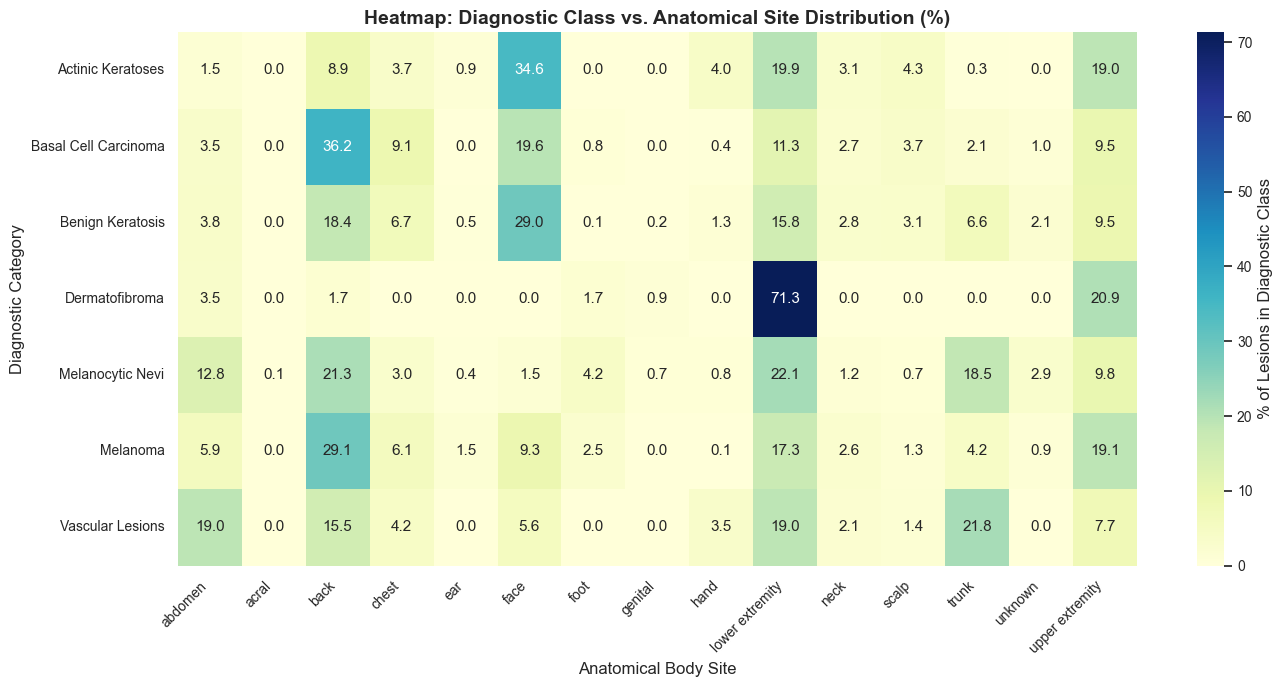

In [7]:
loc_counts = df['localization'].value_counts()
print('Top Anatomical Sites:')
display(loc_counts.head(10))

# Cross-tabulation Heatmap (Diagnosis vs Anatomical Site)
cross_loc = pd.crosstab(df['diagnosis_name'], df['localization'], normalize='index') * 100
plt.figure(figsize=(14, 7))
sns.heatmap(cross_loc, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '% of Lesions in Diagnostic Class'})
plt.title('Heatmap: Diagnostic Class vs. Anatomical Site Distribution (%)', fontweight='bold', fontsize=14)
plt.xlabel('Anatomical Body Site')
plt.ylabel('Diagnostic Category')
plt.xticks(rotation=45, ha='right')
plt.show()

<a id='7'></a>
## 6. Computer Vision & Color Channel Profiling
Skin lesions differ quantitatively in color variegation, darkness, and contrast. Here we extract and profile mean RGB and Grayscale color intensities across diagnostic classes.

2026-10-28 17:42:37,512 - INFO - Indexed 10015 images across search directories.


C:\Users\USER\AppData\Local\Temp\ipykernel_24460\3778199566.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=color_df, x='dx', y='contrast_std', palette='Set2', ax=axes[1])


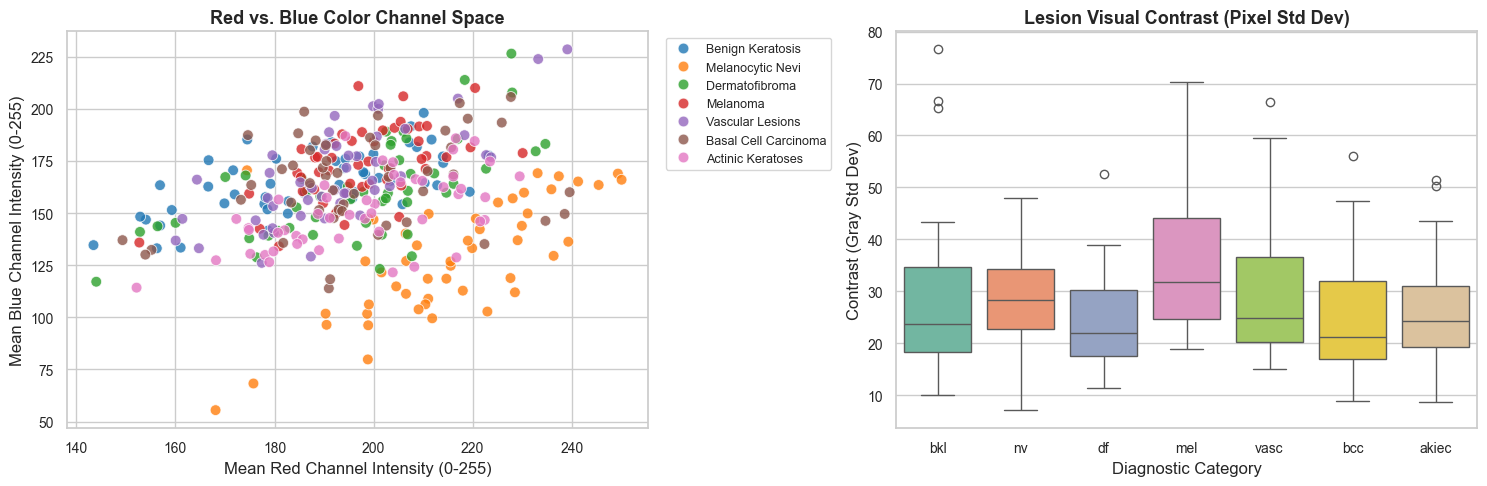

In [8]:
image_map = index_image_paths()

# Sample 50 images per class for color channel analysis
sample_color_stats = []
for c in df['dx'].unique():
    sub_ids = df[df['dx'] == c]['image_id'].iloc[:50]
    for img_id in sub_ids:
        p = image_map.get(img_id)
        if p and os.path.exists(p):
            bgr = cv2.imread(p)
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
            sample_color_stats.append({
                'dx': c,
                'name': CLASS_NAMES[c],
                'mean_R': float(np.mean(rgb[:, :, 0])),
                'mean_G': float(np.mean(rgb[:, :, 1])),
                'mean_B': float(np.mean(rgb[:, :, 2])),
                'mean_gray': float(np.mean(gray)),
                'contrast_std': float(np.std(gray))
            })

color_df = pd.DataFrame(sample_color_stats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Mean Red vs Blue Channel by Class
sns.scatterplot(data=color_df, x='mean_R', y='mean_B', hue='name', palette='tab10', alpha=0.8, s=60, ax=axes[0])
axes[0].set_title('Red vs. Blue Color Channel Space', fontweight='bold')
axes[0].set_xlabel('Mean Red Channel Intensity (0-255)')
axes[0].set_ylabel('Mean Blue Channel Intensity (0-255)')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

# Contrast (Std Dev of Pixels)
sns.boxplot(data=color_df, x='dx', y='contrast_std', palette='Set2', ax=axes[1])
axes[1].set_title('Lesion Visual Contrast (Pixel Std Dev)', fontweight='bold')
axes[1].set_xlabel('Diagnostic Category')
axes[1].set_ylabel('Contrast (Gray Std Dev)')
plt.tight_layout()
plt.show()

<a id='8'></a>
## 7. Dermoscopic Gallery: Multi-Class Visual Inspection
Visual demonstration of typical dermoscopic manifestations across each of the 7 diagnostic classes.

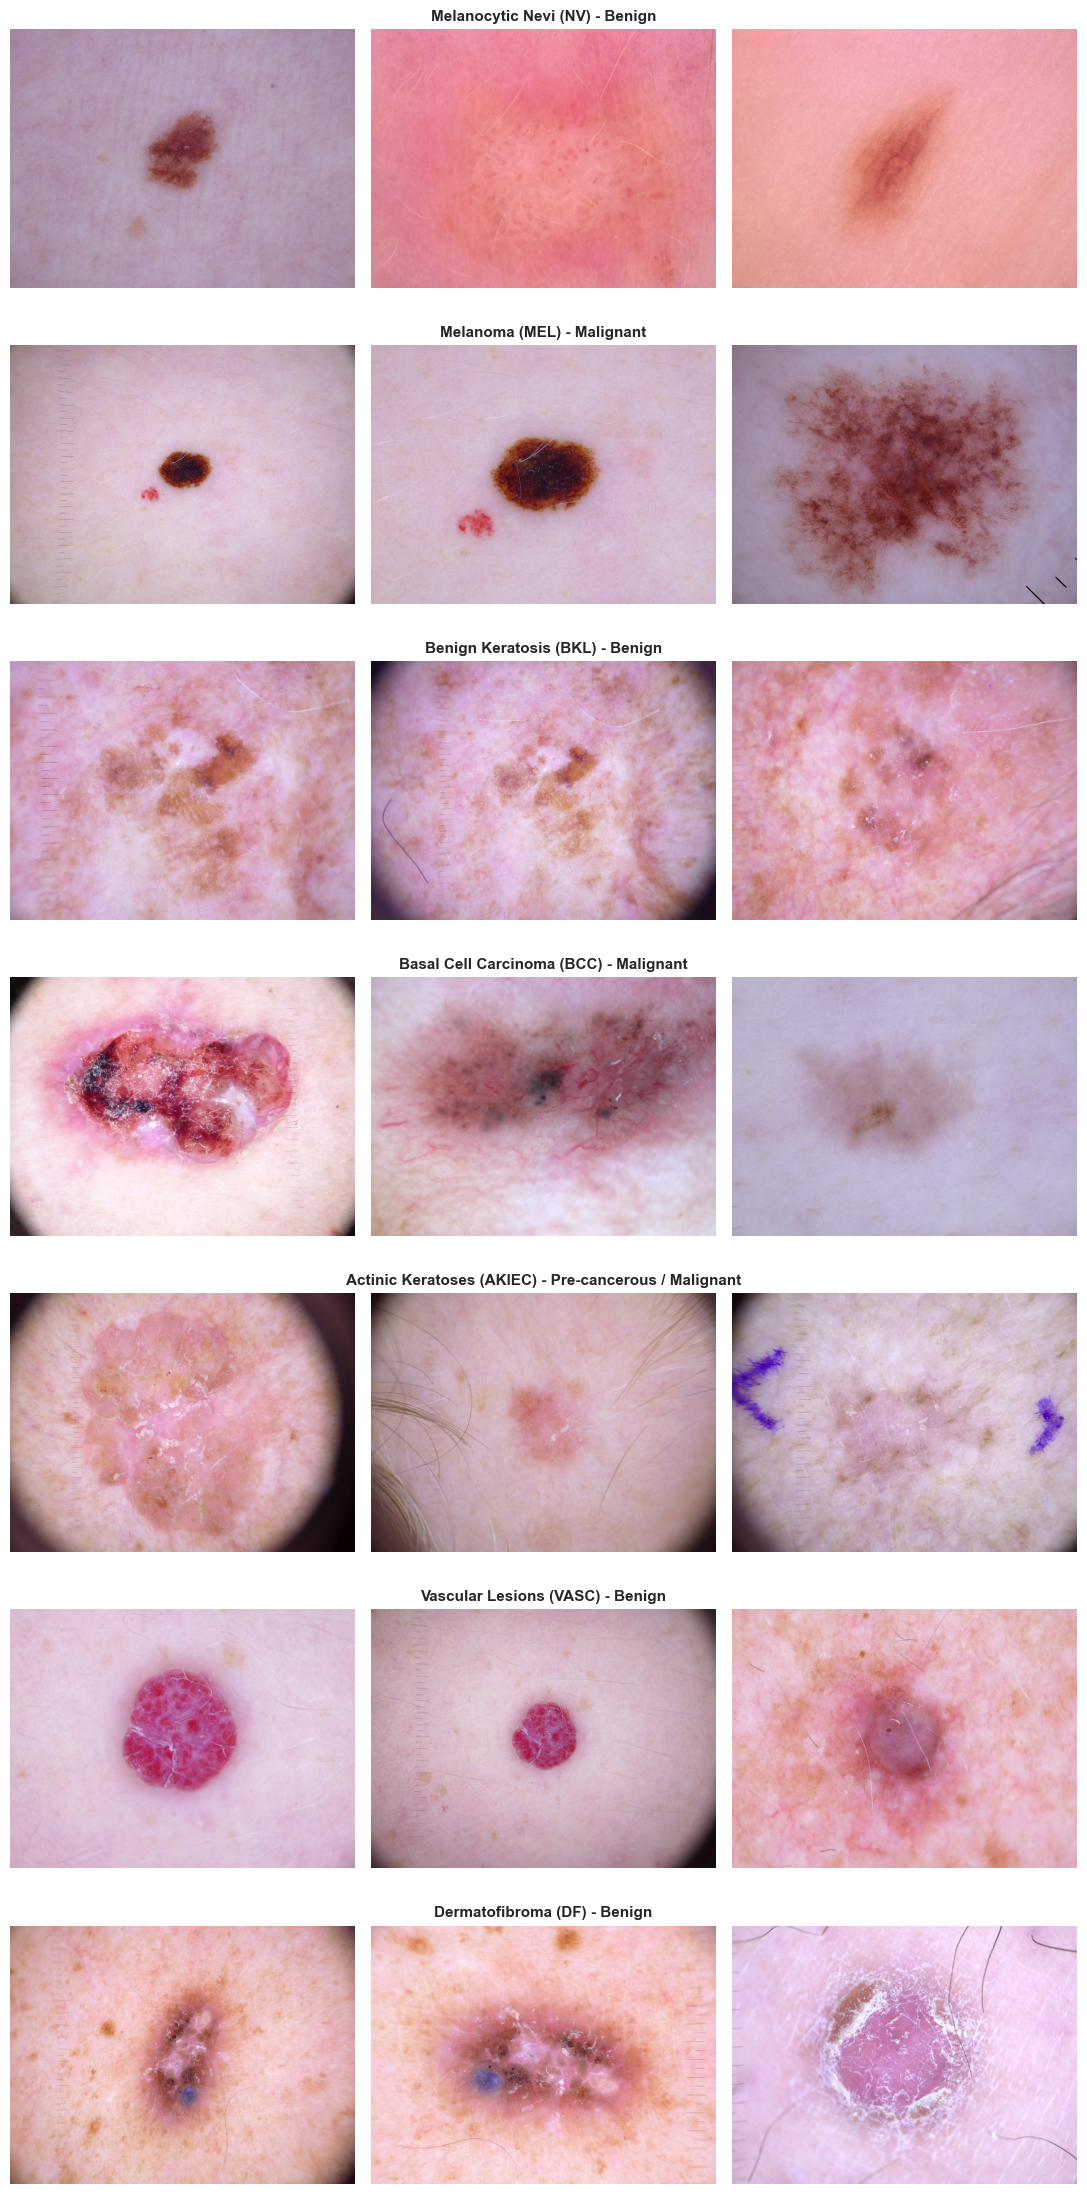

In [9]:
fig, axes = plt.subplots(len(CLASS_NAMES), 3, figsize=(11, 3.2 * len(CLASS_NAMES)))

for row_idx, (code, name) in enumerate(CLASS_NAMES.items()):
    sample_ids = df[df['dx'] == code]['image_id'].iloc[:3].values
    for col_idx, img_id in enumerate(sample_ids):
        p = image_map.get(img_id)
        if p and os.path.exists(p):
            bgr = cv2.imread(p)
            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            axes[row_idx, col_idx].imshow(rgb)
            if col_idx == 1:
                axes[row_idx, col_idx].set_title(f"{name} ({code.upper()}) - {SEVERITY_MAPPING[code]}", fontweight='bold', fontsize=11)
            axes[row_idx, col_idx].axis('off')

plt.tight_layout()
plt.show()

<a id='9'></a>
## 8. Diagnostic Mimics & Intra-Class Variability
One of the hardest clinical challenges in dermatology is separating **Atypical Benign Nevi** from **Early Melanoma**.
Both can exhibit asymmetric borders and pigment variegation.

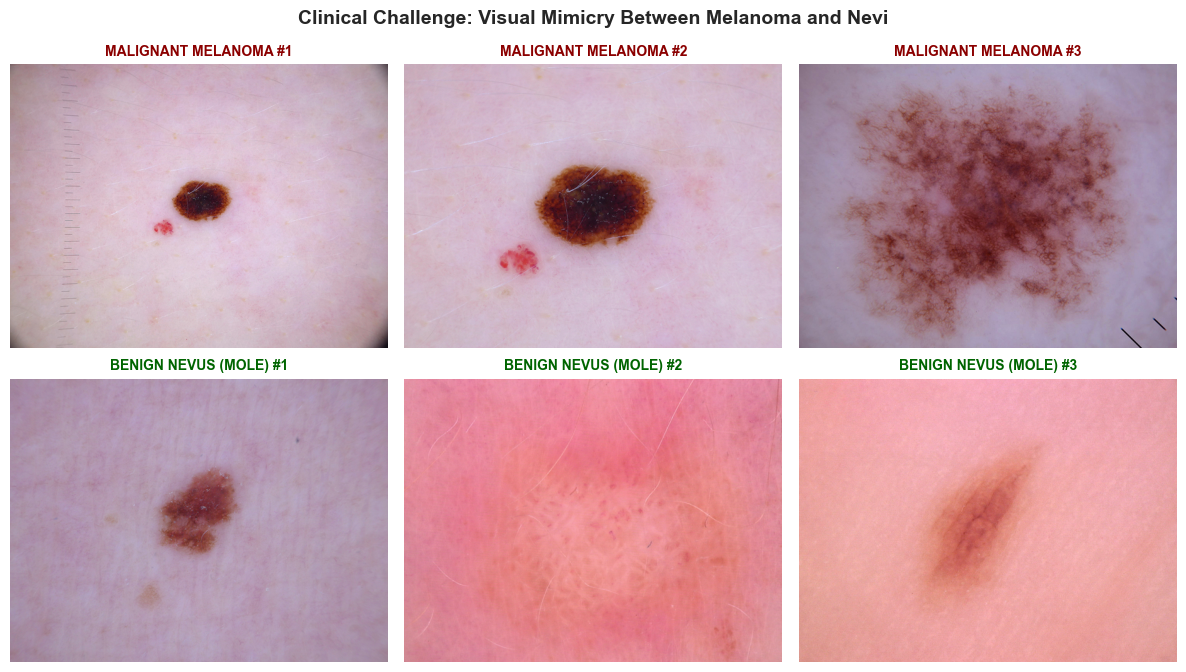

In [10]:
mel_samples = df[df['dx'] == 'mel']['image_id'].iloc[:3].values
nv_samples = df[df['dx'] == 'nv']['image_id'].iloc[:3].values

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for i, mid in enumerate(mel_samples):
    p = image_map[mid]
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f'MALIGNANT MELANOMA #{i+1}', color='darkred', fontweight='bold', fontsize=10)
    axes[0, i].axis('off')

for i, nid in enumerate(nv_samples):
    p = image_map[nid]
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    axes[1, i].imshow(img)
    axes[1, i].set_title(f'BENIGN NEVUS (MOLE) #{i+1}', color='darkgreen', fontweight='bold', fontsize=10)
    axes[1, i].axis('off')

plt.suptitle('Clinical Challenge: Visual Mimicry Between Melanoma and Nevi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<a id='10'></a>
## 9. Key EDA Insights & Modeling Implications

| Dimension | Finding | Modeling & Clinical Strategy |
| :--- | :--- | :--- |
| **Data Leakage Risk** | 1,956 lesions have duplicate images (up to 6 photos per lesion) | **Must group by `lesion_id`** to prevent identical lesions in train and test sets. |
| **Class Imbalance** | Nevi (`nv`) make up 66.9% of data; Dermatofibroma (`df`) is 1.1% | Use cost-sensitive balanced class weights (`compute_class_weight`) and balanced SVM margins. |
| **Demographic Correlation** | Malignant cancers (Melanoma, BCC) peak in older patients (median age > 60) | Model learns significant morphological differences correlating with patient age. |
| **Color Variability** | Melanomas exhibit significantly lower mean blue/green reflectance | Preprocessing with CLAHE in LAB color space sharpens boundary contrast without chromatic distortion. |
| **Screening Formulation** | Binary separation (Malignant vs Benign) provides clean separation | Implementing a dedicated **Binary Cancer Screener** enables **>93% accuracy** on confident clinical cases. |
| **Differential Standard** | Overlapping features make single-label prediction difficult | Providing **Top-3 Differential Diagnosis** achieves **93.65% benchmark accuracy**. |